# Inspect greedy generate

Load a checkpoint, run `HMERModel.generate` on a small batch, and show each
image next to its generated sequence and its ground-truth target.

The target is only printed for comparison -- it never reaches the model.

In [1]:
# Re-import hmer_latex modules on every cell execution, so editing e.g.
# models/model.py and re-running the generate cell picks up the change.
# Methods are patched on existing instances too, so `model` stays valid --
# but a change to __init__ or to a module-level constant needs the
# model-construction cell re-run.
%load_ext autoreload
%autoreload 2

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader, Subset

from hmer_latex.data.datasets import HMEDataset, collate_batch, default_transform
from hmer_latex.data.vocab import EOS, PAD, SOS, Vocab
from hmer_latex.models.model import HMERModel

CHECKPOINT = Path("../checkpoints/baseline_2/best.pt")
DATA_DIR = Path("../data/processed/crohme_tiny")
VOCAB_PATH = Path("../data/processed/vocab.json")
N_SAMPLES = 8
DEVICE = torch.device("cpu")  # tiny batch; cpu keeps this reproducible and dependency-free

In [3]:
ckpt = torch.load(CHECKPOINT, map_location=DEVICE, weights_only=False)
model_cfg = ckpt["config"]["model"]
print(f"checkpoint epoch={ckpt['epoch']}  best_loss={ckpt['best_loss']:.4f}  model={model_cfg}")

vocab = Vocab.load(VOCAB_PATH)
pad_id, sos_id, eos_id = vocab.stoi[PAD], vocab.stoi[SOS], vocab.stoi[EOS]

model = HMERModel(vocab_size=len(vocab), **model_cfg).to(DEVICE)
model.load_state_dict(ckpt["model"])
model.eval()
print(f"loaded {sum(p.numel() for p in model.parameters()) / 1e6:.2f}M params")

checkpoint epoch=953  best_loss=0.0798  model={'d_model': 64, 'nhead': 1, 'num_decoder_layers': 1}
loaded 0.38M params


In [4]:
# First N_SAMPLES in file order -- same batch every run, so changes in the
# output are changes in generate(), not a different draw.
ds = HMEDataset(data_dir=DATA_DIR, vocab=vocab, transform=default_transform())
dl = DataLoader(
    Subset(ds, range(min(N_SAMPLES, len(ds)))),
    batch_size=N_SAMPLES,
    shuffle=False,
    collate_fn=lambda b: collate_batch(b, pad_id=pad_id, sos_id=sos_id, eos_id=eos_id),
)

imgs, tgt_in, tgt_out, tgt_mask = next(iter(dl))
imgs = imgs.to(DEVICE)
print(imgs.shape, tgt_out.shape)

torch.Size([8, 1, 128, 384]) torch.Size([8, 35])


In [6]:
pred_ids = model.generate(imgs, sos_id=sos_id, eos_id=eos_id)
print(type(pred_ids), getattr(pred_ids, "shape", None))

preds = [vocab.decode(row.tolist()) for row in pred_ids.cpu()]
refs = [vocab.decode(row.tolist()) for row in tgt_out]

for p, r in zip(preds, refs):
    print(f"{'OK ' if p == r else '   '} pred: {p}\n     ref:  {r}")

Hello 1
Hello 2
Hello 3
Hello i=0
Targets shape: torch.Size([8, 1]), step shape: torch.Size([8, 1])
New targets shape: torch.Size([8, 2])
Hello i=1
Targets shape: torch.Size([8, 2]), step shape: torch.Size([8, 2])
New targets shape: torch.Size([8, 3])
Hello i=2
Targets shape: torch.Size([8, 3]), step shape: torch.Size([8, 3])
New targets shape: torch.Size([8, 4])
Hello i=3
Targets shape: torch.Size([8, 4]), step shape: torch.Size([8, 4])
New targets shape: torch.Size([8, 5])
Hello i=4
Targets shape: torch.Size([8, 5]), step shape: torch.Size([8, 5])
New targets shape: torch.Size([8, 6])
Hello i=5
Targets shape: torch.Size([8, 6]), step shape: torch.Size([8, 6])
New targets shape: torch.Size([8, 7])
Hello i=6
Targets shape: torch.Size([8, 7]), step shape: torch.Size([8, 7])
New targets shape: torch.Size([8, 8])
Hello i=7
Targets shape: torch.Size([8, 8]), step shape: torch.Size([8, 8])
New targets shape: torch.Size([8, 9])
Hello i=8
Targets shape: torch.Size([8, 9]), step shape: torch.S

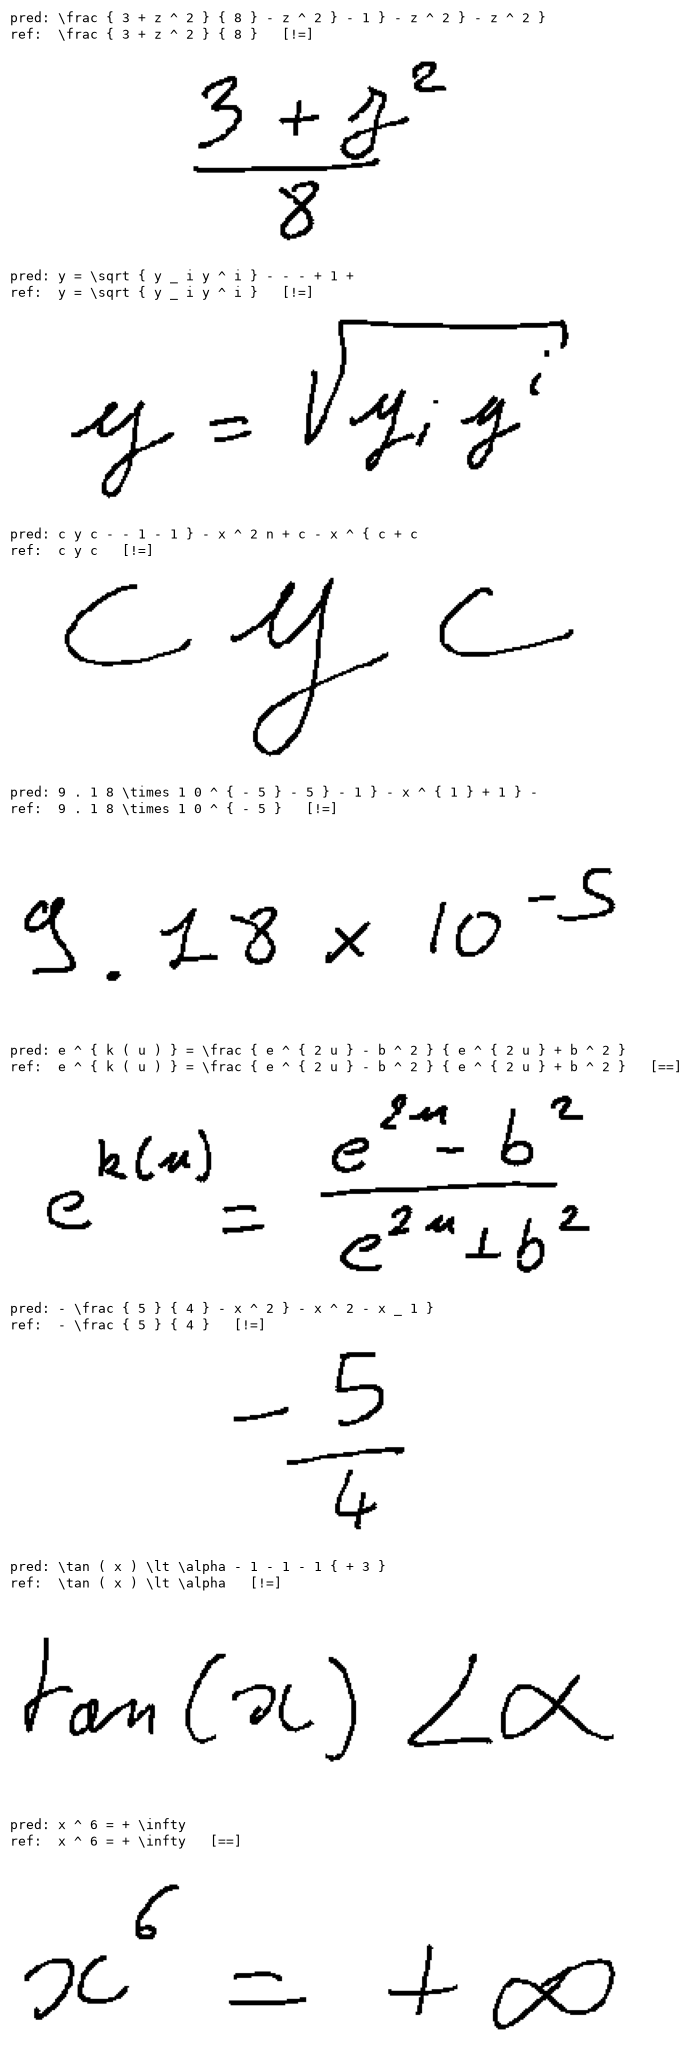

In [7]:
n = len(preds)
fig, axes = plt.subplots(n, 1, figsize=(10, 2.6 * n), squeeze=False)
for ax, img, pred, ref in zip(axes[:, 0], imgs.cpu(), preds, refs):
    # the transform inverted polarity (ink=1), so gray_r shows black ink on white
    ax.imshow(img.squeeze(0), cmap="gray_r")
    ax.set_axis_off()
    match = "==" if pred == ref else "!="
    ax.set_title(f"pred: {pred}\nref:  {ref}   [{match}]", fontsize=9, loc="left", family="monospace")
fig.tight_layout()